In [9]:
from pathlib import Path
import zipfile
# import cv2
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models , Sequential
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.callbacks import EarlyStopping , ModelCheckpoint , ReduceLROnPlateau
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam


In [10]:
split_path = "/kaggle/working/brain_mri_split.npz"

with np.load(split_path) as data:
    X_train = data["X_train"]
    y_train = data["y_train"]
    X_val = data["X_val"]
    y_val = data["y_val"]
    X_test = data["X_test"]
    y_test = data["y_test"]


In [11]:
def preprocess_image(image_path , label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels = 3,
        expand_animations = False
    )
    image.set_shape([None , None , 3])
    image = tf.image.resize(image ,[224 , 224])
    image = preprocess_input(image)

    return image , label

In [12]:
autotune = tf.data.AUTOTUNE
batch_size = 32

train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train), seed=42)
    .map(preprocess_image, num_parallel_calls=autotune)
    .batch(batch_size)
    .prefetch(autotune)
)

val_dataset = (
    val_dataset
    .shuffle(buffer_size=len(X_val) , seed=42)
    .map(preprocess_image , num_parallel_calls=autotune)
    .batch(batch_size)
    .prefetch(autotune)
)

test_dataset = (
    test_dataset
    .shuffle(buffer_size=len(X_test) , seed=42)
    .map(preprocess_image , num_parallel_calls=autotune)
    .batch(batch_size)
    .prefetch(autotune)
)



I0000 00:00:1792698985.049279    4457 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10259 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


In [24]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224 , 224 , 3)
)

base_model.trainable = False 

model = models.Sequential([
    layers.Input(shape=(224 , 224 , 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(4 , activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "home/user/Sync/best_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6
    ),
]

In [16]:
history = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = 15,
    callbacks = callbacks
)

Epoch 1/15


I0000 00:00:1792698991.545791    4596 service.cc:152] XLA service 0x7af7dc0029d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792698991.545814    4596 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-22 19:56:31.654626: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792698992.281189    4596 cuda_dnn.cc:529] Loaded cuDNN version 90300


  7/141 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.3050 - loss: 1.6352

I0000 00:00:1792698997.677229    4596 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6292 - loss: 0.8972

2026-10-22 19:56:47.720024: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1167', 636 bytes spill stores, 636 bytes spill loads

2026-10-22 19:56:48.197406: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1167', 884 bytes spill stores, 884 bytes spill loads

2026-10-22 19:56:51.314138: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1167', 8 bytes spill stores, 8 bytes spill loads

2026-10-22 19:56:51.654294: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1167', 448 bytes spill stores, 448 bytes spill loads



141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 123ms/step - accuracy: 0.6301 - loss: 0.8953 - val_accuracy: 0.8461 - val_loss: 0.4114 - learning_rate: 0.0010
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.8566 - loss: 0.3874 - val_accuracy: 0.8817 - val_loss: 0.3154 - learning_rate: 0.0010
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8789 - loss: 0.3281 - val_accuracy: 0.8915 - val_loss: 0.2781 - learning_rate: 0.0010
Epoch 4/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.8999 - loss: 0.2703 - val_accuracy: 0.9048 - val_loss: 0.2532 - learning_rate: 0.0010
Epoch 5/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9168 - loss: 0.2334 - val_accuracy: 0.9039 - val_loss: 0.2416 - learning_rate: 0.0010
Epoch 6/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9243 - loss: 0.2182 - val_accuracy: 0.9217 - val_loss: 0.2279 - learning_rate: 0.0010
Epoch 7/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9181 - loss: 0.2259 - va

In [35]:
history_tl = history
model_tl = tf.keras.models.clone_model(model)
model_tl.set_weights(model.get_weights())


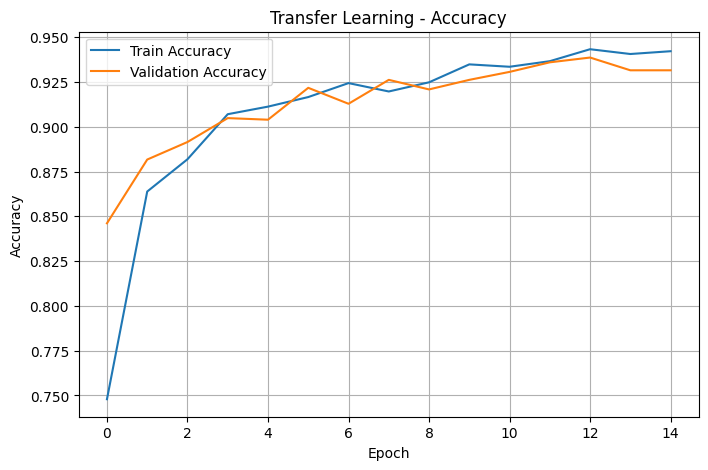

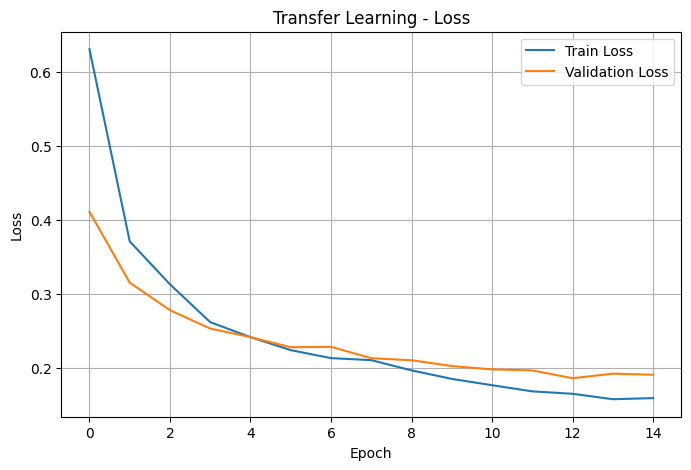

In [38]:
accuracy = history_tl.history["accuracy"]
val_accuracy = history_tl.history["val_accuracy"]
loss = history_tl.history["loss"]
val_loss = history_tl.history["val_loss"]

plt.figure(figsize=(8, 5))
plt.plot(accuracy, label="Train Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.title("Transfer Learning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("Transfer Learning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [39]:
test_loss_tl, test_accuracy_tl = model_tl.evaluate(
    test_dataset,
    verbose=1
)

print(f"Transfer Learning Test Loss: {test_loss_tl:.4f}")
print(f"Transfer Learning Test Accuracy: {test_accuracy_tl:.2%}")


44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.9462 - loss: 0.1484
Transfer Learning Test Loss: 0.1401
Transfer Learning Test Accuracy: 94.95%


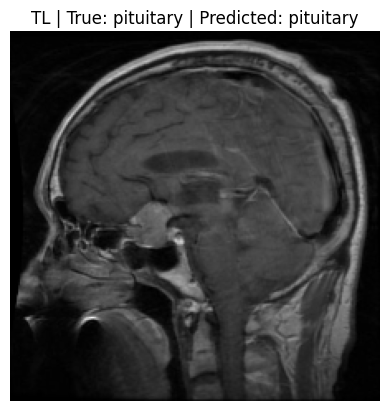

Probabilities: [4.8921448e-03 3.1942632e-03 5.1563559e-04 9.9139798e-01]


In [ ]:
target_names = ["glioma", "meningioma", "notumor", "pituitary"]

for images, labels in test_dataset.take(1):
    image = images[0]
    label = labels[0]

    input_image = tf.expand_dims(image, axis=0)

    probabilities = model_tl.predict(input_image, verbose=0)[0]
    predicted_label = np.argmax(probabilities)

    disp_image = (image.numpy() + 1.0) / 2.0

    plt.imshow(np.clip(disp_image, 0, 1))
    plt.title(
        f"TL | True: {target_names[int(label.numpy())]} | "
        f"Predicted: {target_names[predicted_label]}"
    )
    plt.axis("off")
    plt.show()


In [ ]:
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_prob_tl = model_tl.predict(test_dataset, verbose=1)
y_pred_tl = np.argmax(y_prob_tl, axis=1)

print(classification_report(
    y_true,
    y_pred_tl,
    labels=[0, 1, 2, 3],
    target_names=target_names,
    zero_division=0
))


44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step
Classification Report - Transfer Learning
              precision    recall  f1-score   support

      glioma       0.25      0.24      0.24       324
  meningioma       0.22      0.22      0.22       329
     notumor       0.33      0.33      0.33       400
   pituitary       0.25      0.26      0.26       352

    accuracy                           0.27      1405
   macro avg       0.26      0.26      0.26      1405
weighted avg       0.27      0.27      0.27      1405



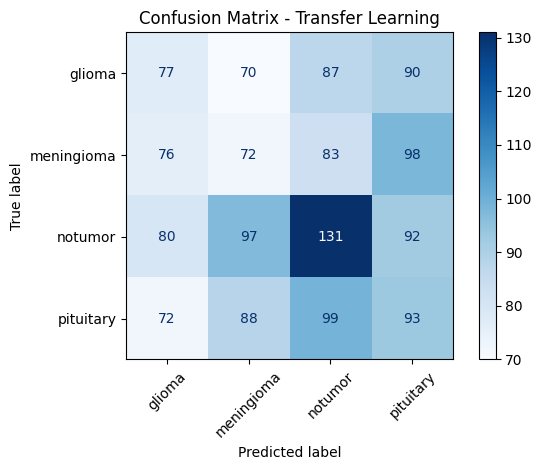

In [42]:
cm_tl = confusion_matrix(y_true, y_pred_tl, labels=[0, 1, 2, 3])

display_tl = ConfusionMatrixDisplay(
    confusion_matrix=cm_tl,
    display_labels=target_names
)

display_tl.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Transfer Learning")
plt.tight_layout()
plt.show()


Fine-Tuning

In [25]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False 
for layer in base_model.layers[-30:]:
    layer.trainable = True
for layer in base_model.layers:
    if isinstance(layer , tf.keras.layers.BatchNormalization):
        layer.trainable = False 

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_fine_tuning = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "home/user/Sync/best_finetuned_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history_fine_tuning = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=callbacks_fine_tuning
)


Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 21s 92ms/step - accuracy: 0.5415 - loss: 1.0712 - val_accuracy: 0.8479 - val_loss: 0.4113 - learning_rate: 1.0000e-05
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.8477 - loss: 0.4325 - val_accuracy: 0.8826 - val_loss: 0.3055 - learning_rate: 1.0000e-05
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8796 - loss: 0.3231 - val_accuracy: 0.9128 - val_loss: 0.2394 - learning_rate: 1.0000e-05
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9061 - loss: 0.2496 - val_accuracy: 0.9235 - val_loss: 0.2154 - learning_rate: 1.0000e-05
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9291 - loss: 0.1979 - val_accuracy: 0.9279 - val_loss: 0.2033 - learning_rate: 1.0000e-05
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9439 - loss: 0.1729 - val_accuracy: 0.9262 - val_loss: 0.1889 - learning_rate: 1.0000e-05
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - ac

In [36]:

history_ft = history_fine_tuning
model_ft = model


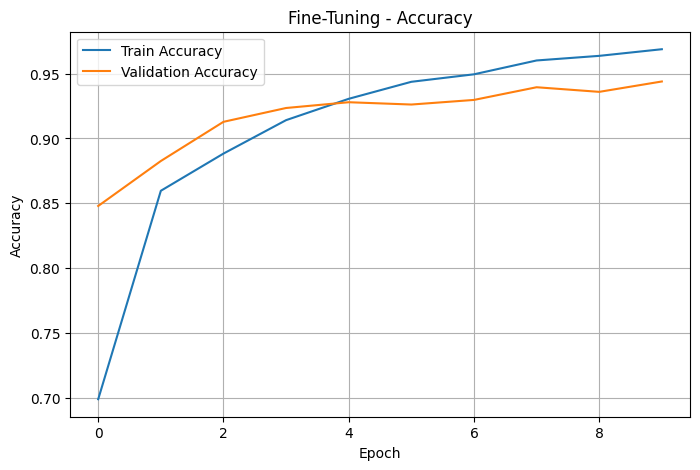

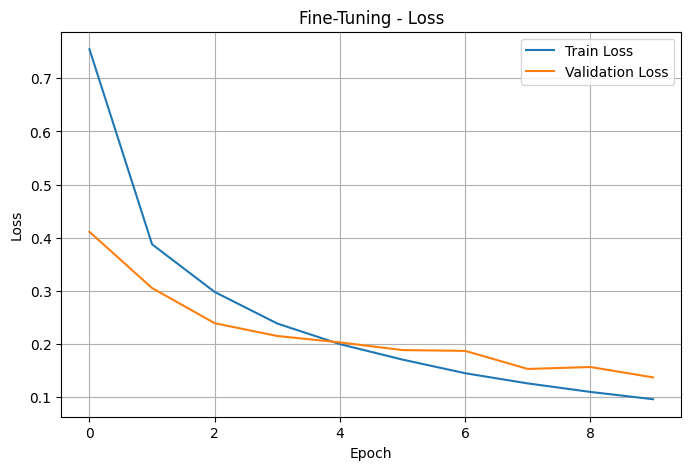

In [43]:

accuracy_ft = history_ft.history["accuracy"]
val_accuracy_ft = history_ft.history["val_accuracy"]
loss_ft = history_ft.history["loss"]
val_loss_ft = history_ft.history["val_loss"]

plt.figure(figsize=(8, 5))
plt.plot(accuracy_ft, label="Train Accuracy")
plt.plot(val_accuracy_ft, label="Validation Accuracy")
plt.title("Fine-Tuning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(loss_ft, label="Train Loss")
plt.plot(val_loss_ft, label="Validation Loss")
plt.title("Fine-Tuning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [44]:

test_loss_ft, test_accuracy_ft = model_ft.evaluate(
    test_dataset,
    verbose=1
)

print(f"Fine-Tuning Test Loss: {test_loss_ft:.4f}")
print(f"Fine-Tuning Test Accuracy: {test_accuracy_ft:.2%}")


44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9471 - loss: 0.1412
Fine-Tuning Test Loss: 0.1401
Fine-Tuning Test Accuracy: 94.95%


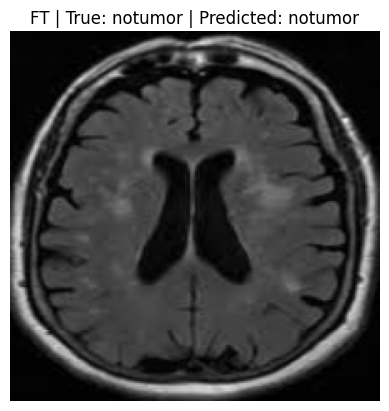

Probabilities: [1.6653715e-07 5.5163447e-04 9.9944323e-01 5.0485223e-06]


In [ ]:

for images, labels in test_dataset.take(1):
    image = images[0]
    label = labels[0]

    input_image = tf.expand_dims(image, axis=0)

    probabilities = model_ft.predict(input_image, verbose=0)[0]
    predicted_label = np.argmax(probabilities)

    disp_image = (image.numpy() + 1.0) / 2.0

    plt.imshow(np.clip(disp_image, 0, 1))
    plt.title(
        f"FT | True: {target_names[int(label.numpy())]} | "
        f"Predicted: {target_names[predicted_label]}"
    )
    plt.axis("off")
    plt.show()

In [46]:

y_prob_ft = model_ft.predict(test_dataset, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

print("Classification Report - Fine-Tuning")

print(classification_report(
    y_true,
    y_pred_ft,
    labels=[0, 1, 2, 3],
    target_names=target_names,
    zero_division=0
))


44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
Classification Report - Fine-Tuning
              precision    recall  f1-score   support

      glioma       0.22      0.21      0.21       324
  meningioma       0.24      0.24      0.24       329
     notumor       0.27      0.27      0.27       400
   pituitary       0.26      0.28      0.27       352

    accuracy                           0.25      1405
   macro avg       0.25      0.25      0.25      1405
weighted avg       0.25      0.25      0.25      1405



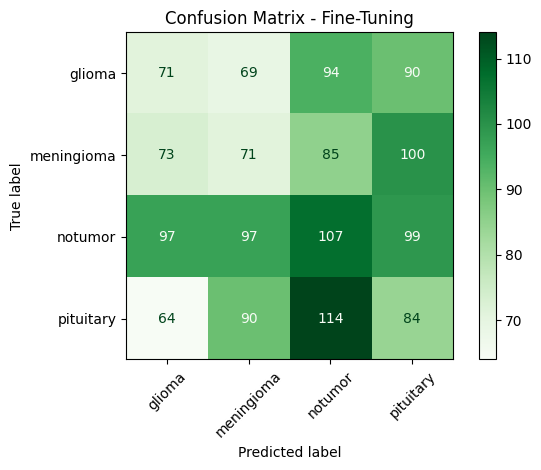

In [48]:

cm_ft = confusion_matrix(y_true, y_pred_ft, labels=[0, 1, 2, 3])

display_ft = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=target_names
)

display_ft.plot(cmap="Greens", xticks_rotation=45)
plt.title("Confusion Matrix - Fine-Tuning")
plt.tight_layout()
plt.show()


In [52]:
print(f"Transfer Learning Test Accuracy: {test_accuracy_tl:.2%}")
print(f"Fine-Tuning Test Accuracy: {test_accuracy_ft:.2%}")

print(f"Transfer Learning Test Loss: {test_loss_tl:.4f}")
print(f"Fine-Tuning Test Loss: {test_loss_ft:.4f}")


Transfer Learning Test Accuracy: 94.95%
Fine-Tuning Test Accuracy: 94.95%
Transfer Learning Test Loss: 0.1401
Fine-Tuning Test Loss: 0.1401
